# Stage 0. Preparation


In the preparation stage we check the ABM model in netlogo, set the seed, horizon, number of repetitions R, and choose a screening plan. The results of the preparation stage are stored in the csv files discussed later 

`abm_runner.py` module is used to run the ABM model. The module uses JPype to start a JVM with NetLogo and run the model. The module also provides a function to read the results of the model and store them in a csv file.

## 0.1. Environment

In [1]:
import json, hashlib, math, os, platform, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# set pandas display options
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

# Set the color palette for plots
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110,
                     "axes.prop_cycle": plt.cycler(color=C)})

## 0.2. Config

Note 1: the parameter L4-subsidy doesnt affect the dynamics itself, however, it affects the outcome: K2 = L4-subsidy * import. Keep the subsidy at the value from the model, and recalculate K2 for a different subsidy without running the model.

Note 2: the parameter L3 doesnt affect the dynamics itself, however, it affects the outcome: K3 = c3 * ref-price * K3-volume


In [2]:
# paths depend on the operating system and downloaded version
NETLOGO_HOME = r"C:\Program Files\NetLogo 7.0.4"
MODEL_PATH = Path(r"refinery_shock_abm.nlogox")
OUT_DIR = Path("results")
OUT_DIR.mkdir(exist_ok=True)

# time horizon and checkpoints for KPI collection
HORIZON = 365

CHECKPOINTS = [30, 90, 180, HORIZON]

# A damaged refinery provides ~1/3 of the market,
# so the market loss is ~ shock-depth / 3.
SHOCK_LEVELS = [0.2, 0.45, 0.7]
SHOCK_MID = 0.45

# levers and their ranges for the experiment
LEVERS = {  # short names for the levers in the model interface
    "L2": "L2-export-ban?", "L3": "L3-quality-relax?", "L4": "L4-import?",
    "L5": "L5-fillup-limit?", "L6": "L6-price-cap?",
}
LEVER_RANGES = {  # used later for screening and optimization; values are (min, max) for sliders
    "L3-share-naphtha":     (0.0, 0.5),
    "L4-import-limit":      (0.0, 0.3),
    "L5-liters-per-fillup": (10, 70),
    "L6-price-cap":         (1.0, 2.0),
}
# levers that are fixed to "on" (True) for all experiments;
# set in the screening stage
LEVER_ON = None


# uncertainty parameters and their ranges for the experiment
UNC_RANGES = {
    "panic-sensitivity": (0.5, 2.0),     
    "tau-down":          (7, 30),        
    "w-own-experience":  (0.2, 0.8),     
    "price-elasticity":  (-0.4, -0.05),
    "normal-surplus":    (0.02, 0.12),   
}
C3_RANGE = (0.05, 0.5)

# reproducibility: master seed and number of seeds for each stage
MASTER_SEED = 20261119
SEED_POOLS = {"diag": 10, "pilot": 30, "screening": 50,
              "levels": 30, "robust": 30, "validation": 50}


KPIS = ["K0", "K1", "K2", "K3_volume", "K4", "K5_hours"]
KPI_NAME = {"K0": "physical deficit, L", "K1": "demand, displaced by price, L",
            "K2": "import subsidy, m.u.", "K3_volume": "low-grade gasoline, L",
            "K4": "consumer overpayment, m.u.", "K5_hours": "queues, machine-hours"}

In [3]:
# parallelization settings
N_WORKERS_MAX = max(1, (os.cpu_count() or 2) - 1)
JVM_ARGS = ["-Xmx1g"]

## 0.4. Connecting to NetLogo

From the model read the default values of the sliders (levers) and all constants after `setup`. 

Note: The SHA-256 of the model file fixes the version: if the file changes, results from different stages cannot be mixed.

In [4]:
import importlib
import abm_runner as ar

importlib.reload(ar) 

<module 'abm_runner' from 'c:\\Users\\arsmi\\Downloads\\netlogo-project\\Experiments\\abm_runner.py'>

In [5]:
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

# writing down model version for further check
MODEL_SHA256 = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()

# setting up the base configuration for the model run
BASE_CFG = {"netlogo_home": NETLOGO_HOME, "model_path": str(MODEL_PATH.resolve()),
            "jvmargs": JVM_ARGS, "jvm_path": ar.find_jvm(NETLOGO_HOME),
            "horizon": HORIZON, "checkpoints": CHECKPOINTS}
print("JVM:", BASE_CFG["jvm_path"])

# connecting to NetLogo
link = ar.make_link(BASE_CFG)
NETLOGO_VERSION = link.report("netlogo-version")
print("NetLogo", NETLOGO_VERSION, "| model sha256:", MODEL_SHA256[:16], "...")

# reading the default values of sliders (levers) and all constants after `setup`
slider_vals = dict(zip(ar.SLIDERS, np.atleast_1d(
    link.report(ar.nl_list(ar.SLIDERS))).tolist()))
# P0: all switches off, sliders at default values
INTERFACE_DEFAULTS = {sw: False for sw in ar.SWITCHES} | slider_vals
INTERFACE_DEFAULTS["shock-depth"] = SHOCK_MID
if LEVER_ON is None:
    LEVER_ON = {k: slider_vals[k] for k in LEVER_RANGES}
print("Sliders in the model file:", slider_vals)
print("Levels 'on' for screening:", LEVER_ON)

# constants are read after `setup` to get the nominal values of uncertain parameters
link.command(" ".join(f"set {k} {ar.nl_value(v)}" for k,
             v in INTERFACE_DEFAULTS.items()) + " set seed 1 setup")
CONSTANTS = dict(zip(ar.CONSTANT_REPORTERS,
                     np.atleast_1d(link.report(ar.nl_list(ar.CONSTANT_REPORTERS))).tolist()))
NOMINAL_UNC = {k: CONSTANTS[k] for k in ar.UNCERTAIN}
print("Nominal uncertain parameters:", NOMINAL_UNC)

CFG = BASE_CFG | {"interface_defaults": INTERFACE_DEFAULTS,
                  "nominal_uncertain": NOMINAL_UNC}
pd.Series(CONSTANTS, name="value").to_frame()

JVM: C:\Program Files\NetLogo 7.0.4\runtime\bin\server\jvm.dll
NetLogo 7.0.4 | model sha256: 2b246166dc0c1182 ...
Sliders in the model file: {'L3-share-naphtha': 0.15, 'L4-import-limit': 0.1, 'L4-subsidy': 0.25, 'L5-liters-per-fillup': 30.0, 'L6-price-cap': 1.1, 'shock-depth': 0.5}
Levels 'on' for screening: {'L3-share-naphtha': 0.15, 'L4-import-limit': 0.1, 'L5-liters-per-fillup': 30.0, 'L6-price-cap': 1.1}
Nominal uncertain parameters: {'panic-sensitivity': 1.0, 'tau-down': 14.0, 'w-own-experience': 0.5, 'price-elasticity': -0.2, 'normal-surplus': 0.06}


,value
shock-start,5.000000
policy-delay,8.000000
L3-ramp-days,7.000000
L4-import-delay,14.000000
n-refineries,3.000000
n-stations,40.000000
n-consumers,5000.000000
normal-surplus,0.060000
naphtha-ratio,0.600000
refinery-storage-days,7.000000


## 1. Seed sets

All seeds are taken from one generator `MASTER_SEED` and divided into **non-overlapping** pools: the check at stage 5 is done on seeds that the model has «not seen». Within a stage, all combinations of levers use the same seeds (common random numbers, CRN): repeat r = seed r. The `seed` slider in the model is 0-1000, `seed = 0` means a random seed, so we take 1-1000.


In [6]:
_rng = np.random.default_rng(MASTER_SEED)
_perm = _rng.permutation(np.arange(1, 1001)).tolist()
SEEDS, i = {}, 0
for name, n in SEED_POOLS.items():
    SEEDS[name] = _perm[i:i + n]
    i += n

assert len(set(sum(SEEDS.values(), []))) == i, "one seed is used in more than one pool"
(OUT_DIR / "seeds.json").write_text(json.dumps({"master_seed": MASTER_SEED, "pools": SEEDS}, indent=1))
{k: v[:5] for k, v in SEEDS.items()}

{'diag': [619, 16, 466, 973, 778],
 'pilot': [392, 334, 8, 972, 568],
 'screening': [347, 164, 159, 797, 98],
 'levels': [591, 763, 194, 329, 233],
 'robust': [611, 262, 984, 657, 156],
 'validation': [379, 840, 676, 490, 279]}

In [7]:
# DEPRECATED
# # This helper is kept for P1/P2 setup only; do not use in new notebooks
def policy(*levers, **strength):
    
    """This function creates a policy configuration for the model run.
    It takes a variable number of lever names and optional strength parameters,
    returning a dictionary that represents the policy settings.
    
    Parameters:
        levers: Variable number of lever names (e.g., "L2", "L3") to be set to True in the policy.
        strength: Optional keyword arguments representing additional parameters
      for the policy, which will be added to the returned dictionary.
    
    Returns:
        A dictionary containing the policy settings, with specified levers set to True,
        the default lever settings from LEVER_ON, and any additional strength parameters.
    
    """
    p = {LEVERS[l]: True for l in levers}
    p.update(LEVER_ON)
    p.update(strength)
    return p


POLICIES = {"P0": policy(), "P1": policy("L3", "L5", "L6"), "P2": policy("L2", "L4"),
            "ALL": policy("L2", "L3", "L4", "L5", "L6")}

def job(seed, pol="P0", shock=SHOCK_MID, unc=None, stage="diag", design_id=None, tag=None, **labels):
    """This function creates a job configuration for the model run.

    
    Parameters:
        seed: The random seed for the model run.
        pol: The policy to be applied, either as a string key from POLICIES
        shock: The shock level to be applied in the model run.
        unc: A dictionary of uncertainty parameters to be applied in the model run.
        stage: The stage of the experiment (e.g., "diag", "pilot").
        design_id: An optional design ID for the job configuration.
        tag: An optional tag to be added to the run ID.
        labels: Additional keyword arguments representing labels for the job configuration.
    
    Returns:
        A dictionary containing the job configuration, including the run ID, stage, design ID,
        shock level, seed, policy parameters, uncertainty parameters, and any additional labels.
    
    """
     
    if isinstance(pol, str):
        params, design_id = POLICIES[pol] | {"shock-depth": shock}, pol
    else:
        params = pol | {"shock-depth": shock}
    run_id = f"{stage}|{design_id}|sd={shock}|seed={seed}" + (f"|{tag}" if tag else "")
    return {"run_id": run_id, "stage": stage, "design_id": design_id, "shock": shock, "seed": int(seed),
            "params": params, "uncertain": unc, **labels}


In [8]:
CHECKS = {}
def check(name, ok, detail=""):
    """This function records the result of a check and prints the outcome.
    It takes a name for the check, a boolean indicating whether the check passed,
    and an optional detail message. The result is stored in the CHECKS dictionary,
    and a message is printed to indicate whether the check passed or failed.
    
    Parameters:
        name: A string representing the name of the check.
        ok: A boolean indicating whether the check passed (True) or failed (False).
        detail: An optional string providing additional details about the check result.
    
    Returns:
        None. The function updates the CHECKS dictionary and prints the check result.
    """
    
    CHECKS[name] = {"ok": bool(ok), "detail": str(detail)}
    print(("PASS " if ok else "FAIL ") + name + (f" | {detail}" if detail else ""))

## 2. Model checks

The model is checked for reproducibility and non-interference of reading. The checks are done by running the model with the same seed twice and comparing the results. The results should be identical, and reading the state of the model should not change the trajectory of the model.

### 2.1. Reproducibility and non-interference of reading

One seed run twice in a row should produce bitwise identical KPIs. Daily reading of the model state (`run_timeseries`) should not change the trajectory: all model reporters are wrapped in `with-local-randomness`.

In [9]:
s = SEEDS["diag"][0]
j = job(s, "ALL")
a, b = ar.run_one(link, j, CFG), ar.run_one(link, j, CFG)
ts = ar.run_timeseries(link, j, CFG)
same = all(a[k] == b[k] for k in KPIS)
check("same seed -> same KPIs", same, {k: a[k] for k in KPIS})
same_ts = all(np.isclose(ts.iloc[-1][r], a[k], rtol=0, atol=0)
              for k, r in [("K0", "K0-total"), ("K4", "K4-total"), ("K5_hours", "K5-total-hours")])
check("daily readout does not alter the trajectory", same_ts)
print(f"single run of {HORIZON} days: {a['sec']:.1f} s")

PASS same seed -> same KPIs | {'K0': 2076.324746193259, 'K1': 94894.47815616099, 'K2': 124363.51146891803, 'K3_volume': 408447.8626125753, 'K4': 499611.5377961495, 'K5_hours': 67306.80533333427}
PASS daily readout does not alter the trajectory
single run of 365 days: 51.5 s


### 2.2. Override of uncertainty constants

(a) Nominal values via `override_command` give the same run as without override (bitwise).
(b) `panic-sensitivity` scales `panic-i`; `normal-surplus` scales the capacity of the NPS, and the random flow does not shift (`policy-delay` and the city are the same).
(c) The direction of effects is reasonable: stronger panic -> more deficit; more `normal-surplus` -> less deficit with P0.

In [10]:
s = SEEDS["diag"][1]
base = ar.run_one(link, job(s, "P0"), CFG)
nom = ar.run_one(link, job(s, "P0", unc=dict(NOMINAL_UNC), tag="nominal"), CFG)
check("(a) nominal override = no override", all(base[k] == nom[k] for k in KPIS))

def probe(unc):
    """This function probes the model with a given uncertainty configuration.
    It runs the model with the specified uncertainty parameters and returns a list of key metrics.
    
    Parameters:
        unc: A dictionary of uncertainty parameters to be applied in the model run.
    
    Returns:
        A list of key metrics from the model run.
    """    
    j = job(s, "P0", unc=unc, tag="probe")
    ar._prepare(link, j, CFG)
    r = link.report("(list mean [panic-i] of consumers  sum [capacity] of refineries  policy-delay  "
                    "[xcor] of min-one-of consumers [who])")
    return np.atleast_1d(r).tolist()

p0 = probe(None)
p1 = probe({"panic-sensitivity": 2.0, "normal-surplus": 0.12})
# checks for the effects of uncertainty parameters on model outputs
check("(b) panic-i x2", math.isclose(p1[0] / p0[0], 2.0 / NOMINAL_UNC["panic-sensitivity"], rel_tol=1e-9),
      f"{p0[0]:.4f} -> {p1[0]:.4f}")
check("(b) capacity x (1.12/1.06)", math.isclose(p1[1] / p0[1], 1.12 / (1 + NOMINAL_UNC["normal-surplus"]), rel_tol=1e-9))
check("(b) random stream not shifted (policy-delay, coordinates)", p0[2] == p1[2] and p0[3] == p1[3])


lo = ar.run_one(link, job(s, "P0", unc={"panic-sensitivity": 0.5}, tag="lo"), CFG)
hi = ar.run_one(link, job(s, "P0", unc={"panic-sensitivity": 2.0}, tag="hi"), CFG)
check("(c) panic 2.0 yields higher K0 than 0.5", hi["K0"] > lo["K0"], f"{lo['K0']:.0f} vs {hi['K0']:.0f}")
l2 = policy("L2")
ns_lo = ar.run_one(link, job(s, l2, design_id="L2", unc={"normal-surplus": 0.02}, tag="ns_lo"), CFG)
ns_hi = ar.run_one(link, job(s, l2, design_id="L2", unc={"normal-surplus": 0.12}, tag="ns_hi"), CFG)
check("(c) under L2: normal-surplus 0.12 yields lower K0 than 0.02", ns_hi["K0"] < ns_lo["K0"],
      f"{ns_lo['K0']:.0f} vs {ns_hi['K0']:.0f}")

PASS (a) nominal override = no override
PASS (b) panic-i x2 | 1.0002 -> 2.0004
PASS (b) capacity x (1.12/1.06)
PASS (b) random stream not shifted (policy-delay, coordinates)
PASS (c) panic 2.0 yields higher K0 than 0.5 | 8826 vs 45969
PASS (c) under L2: normal-surplus 0.12 yields lower K0 than 0.02 | 27367 vs 923


### 2.3. No shock norm

`shock-depth = 0`, all levels are disabled

FAIL C1: price 1 ± 0.03 after day 20 | min 0.980, max 1.035
PASS C1: K0 ~ 0 | K0 = 0.0 L
FAIL C1: dry-share < 0.05 | max 0.100


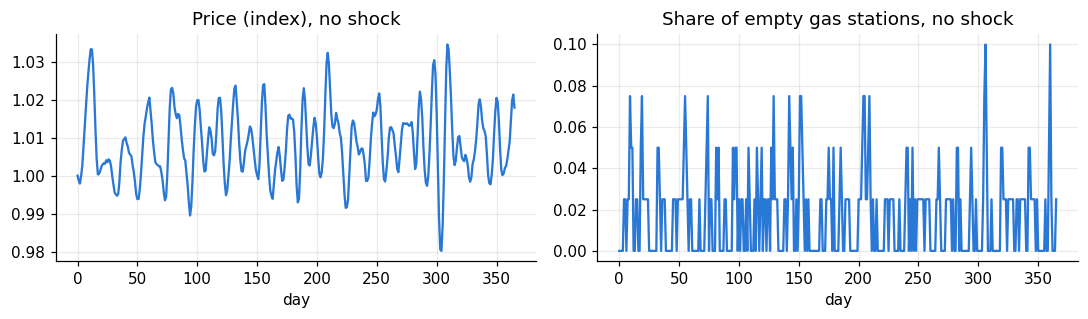

In [11]:
ts0 = ar.run_timeseries(link, job(SEEDS["diag"][2], "P0", shock=0.0), CFG)
after = ts0[ts0.ticks >= 20]


check("C1: price 1 ± 0.03 after day 20", after.price.between(0.97, 1.03).all(),
      f"min {after.price.min():.3f}, max {after.price.max():.3f}")
check("C1: K0 ~ 0", ts0["K0-total"].iloc[-1] < 1e-6 * CONSTANTS["D0"] * HORIZON, f"K0 = {ts0['K0-total'].iloc[-1]:.1f} L")
check("C1: dry-share < 0.05", ts0["dry-share"].max() < 0.05, f"max {ts0['dry-share'].max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(ts0.ticks, ts0.price); ax[0].set_title("Price (index), no shock"); ax[0].set_xlabel("day")
ax[1].plot(ts0.ticks, ts0["dry-share"]); ax[1].set_title("Share of empty gas stations, no shock"); ax[1].set_xlabel("day")
plt.tight_layout(); plt.show()

### 2.4. Mass Balance

For the shock scenario and all measures: the change in total inventories (refineries + in transit + gas stations + vehicles) per day equals production − export + import − actual consumption (consumption − K0 per day). The remaining amount should be at the level of rounding error.

In [12]:
tsb = ar.run_timeseries(link, job(SEEDS["diag"][3], "ALL", shock=SHOCK_LEVELS[-1]), CFG)
stock = tsb[["total-refinery-stock", "total-pipeline-stock", "total-station-stock", "total-consumer-stock"]].sum(axis=1)
flow = (tsb["production-today"] - tsb["export-today"] + tsb["import-today"]
        - (tsb["consumption-today"] - tsb["K0-today"]))
resid = (stock.diff() - flow).iloc[1:]
rel = resid.abs().max() / CONSTANTS["D0"]
check("mass balance", rel < 1e-6, f"max |residual| = {resid.abs().max():.2e} L ({rel:.1e} D0)")

PASS mass balance | max |residual| = 1.26e-09 L (8.4e-14 D0)


### 2.5. Horizon and control points

Shock is constant, so the accumulated KPIs over a year mainly reflect the **new steady state**, not the acute panic phase. The table shows what fraction of the annual value is accumulated by day 30/90/180. 



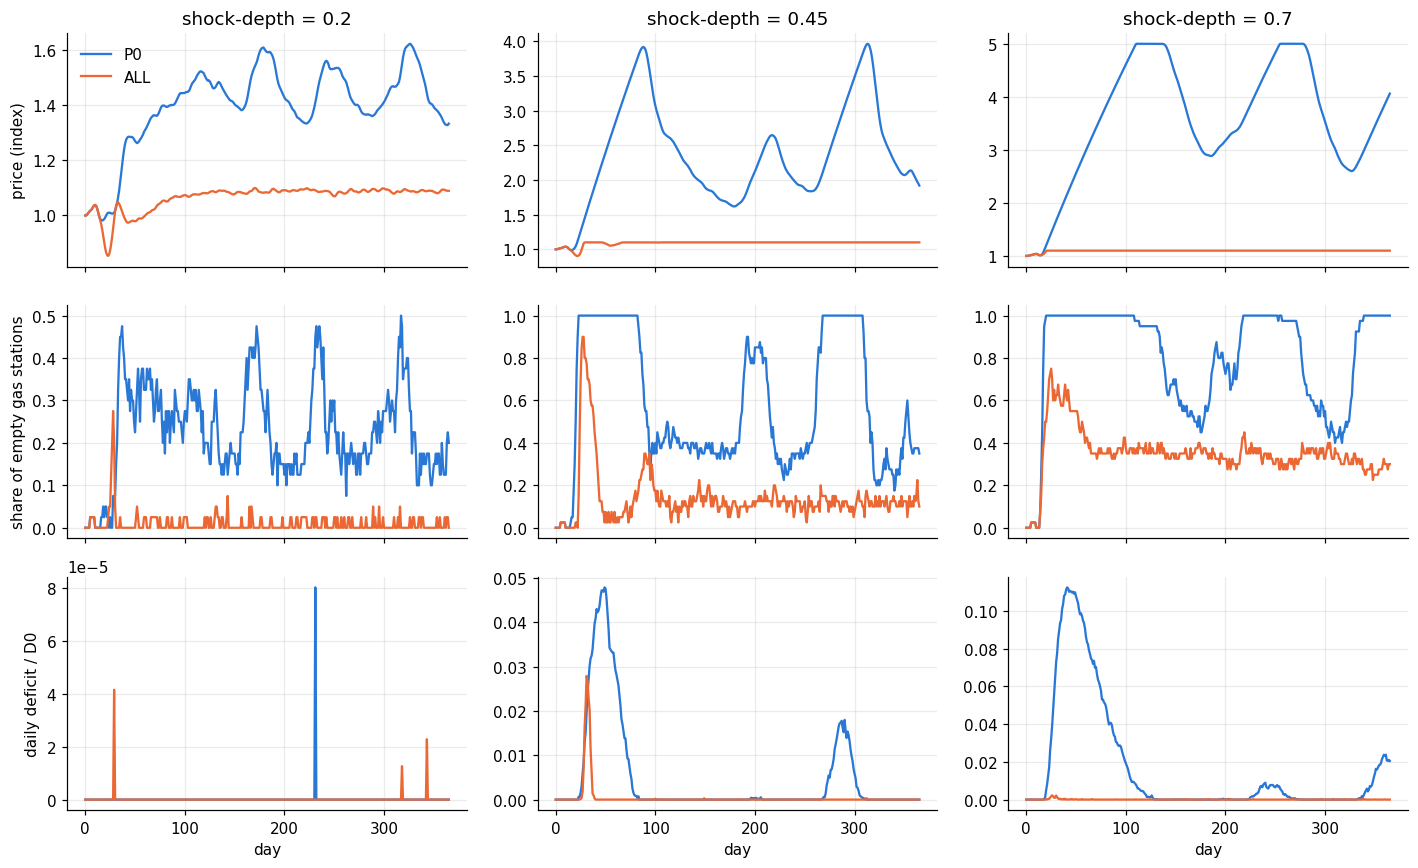

,shock,policy,K0: share by day 30,K0: share by day 90,K0: share by day 180,K4: share by day 30,K4: share by day 90,K4: share by day 180,K5: share by day 30,K5: share by day 90,K5: share by day 180
0,0.20,P0,0.00,0.00,0.00,0.00,0.13,0.42,0.10,0.28,0.52
1,0.20,ALL,0.54,0.54,0.54,0.01,0.07,0.36,0.06,0.23,0.48
2,0.45,P0,0.03,0.80,0.80,0.01,0.23,0.46,0.21,0.31,0.52
3,0.45,ALL,0.28,0.99,1.00,0.02,0.18,0.45,0.15,0.41,0.60
4,0.70,P0,0.06,0.83,0.90,0.01,0.13,0.45,0.08,0.12,0.59
5,0.70,ALL,0.54,0.79,0.83,0.05,0.22,0.47,0.10,0.25,0.48


In [13]:
diag = {}
for shock in SHOCK_LEVELS:
    for pol in ["P0", "ALL"]:
        # run the model for each combination of shock level and policy,
        # storing the results in the diag dictionary
        diag[(shock, pol)] = ar.run_timeseries(link, job(SEEDS["diag"][4], pol, shock=shock), CFG)

fig, axes = plt.subplots(3, 3, figsize=(13, 8), sharex=True)
# output the results of the runs for each shock level and policy,
# plotting price, share of empty gas stations, and daily deficit
for col, shock in enumerate(SHOCK_LEVELS):
    for i, pol in enumerate(["P0", "ALL"]):
        d = diag[(shock, pol)]
        axes[0, col].plot(d.ticks, d.price, color=C[i], label=pol)
        axes[1, col].plot(d.ticks, d["dry-share"], color=C[i], label=pol)
        axes[2, col].plot(d.ticks, d["K0-today"] / CONSTANTS["D0"], color=C[i], label=pol)
    axes[0, col].set_title(f"shock-depth = {shock}")
axes[0, 0].set_ylabel("price (index)"); axes[1, 0].set_ylabel("share of empty gas stations")
axes[2, 0].set_ylabel("daily deficit / D0")
for a in axes[2]: a.set_xlabel("day")
axes[0, 0].legend(frameon=False)
plt.tight_layout(); plt.show()

# output a summary table showing the fraction of annual KPI values
# accumulated by specific checkpoints (days 30, 90, 180, and 365)
# for each combination of shock level and policy
rows = []
for (shock, pol), d in diag.items():
    r = {"shock": shock, "policy": pol}
    for k, col in [("K0", "K0-total"), ("K4", "K4-total"), ("K5", "K5-total-hours")]:
        tot = d[col].iloc[-1]
        for cp in CHECKPOINTS[:-1]:
            r[f"{k}: share by day {cp}"] = d[col].iloc[cp] / tot if tot > 0 else np.nan
    rows.append(r)
pd.DataFrame(rows).round(2)

In [14]:
# Background without shock (C1) and absolute KPIs for the horizon table
d = ts0[ts0.ticks >= 20]
print(f"price without shock: mean {d.price.mean():.3f}, sd {d.price.std():.3f}, "
      f"days outside 1 ± 0.03: {(~d.price.between(0.97, 1.03)).sum()} of {len(d)}")
print(f"dry-share without shock: mean {d['dry-share'].mean():.3f}, "
      f"days > 0.05: {(d['dry-share'] > 0.05).sum()} of {len(d)}")
print("background over the year without shock:", {k: round(ts0[c].iloc[-1]) for k, c in
      [("K1", "K1-total"), ("K4", "K4-total"), ("K5", "K5-total-hours")]})

D0 = CONSTANTS["D0"]
rows = []
for (shock, pol), x in diag.items():
    rows.append({"shock": shock, "policy": pol,
                 "K0 (days of demand D0)": x["K0-total"].iloc[-1] / D0,
                 "K1 (days of D0)": x["K1-total"].iloc[-1] / D0,
                 "K4, m.u.": x["K4-total"].iloc[-1],
                 "K5, h/car": x["K5-total-hours"].iloc[-1] / CONSTANTS["n-consumers"],
                 "price by end of year": x["price"].iloc[-1]})
pd.DataFrame(rows).round(2)

price without shock: mean 1.008, sd 0.009, days outside 1 ± 0.03: 4 of 346
dry-share without shock: mean 0.017, days > 0.05: 12 of 346
background over the year without shock: {'K1': 9878, 'K4': 49064, 'K5': 14606}


,shock,policy,K0 (days of demand D0),K1 (days of D0),"K4, m.u.","K5, h/car",price by end of year
0,0.20,P0,0.00,22.93,2079850.02,2.82,1.33
1,0.20,ALL,0.00,4.81,376890.27,9.71,1.09
2,0.45,P0,1.79,53.69,6679480.80,2.55,1.92
3,0.45,ALL,0.17,6.31,498317.89,13.24,1.10
4,0.70,P0,6.17,76.93,12241774.54,5.25,4.06
5,0.70,ALL,0.02,6.59,519319.28,17.50,1.10


## 3. Run Time and Parallelism

We measure the time of a single run in the notebook process and the throughput of the pool at different numbers of processes (each has its own JVM, JVM startup and model loading are included in the measurement). Then the budget for all stages is calculated based on the best throughput.

In [15]:
import importlib
import batch_runner as br

importlib.reload(br)

<module 'batch_runner' from 'c:\\Users\\arsmi\\Downloads\\netlogo-project\\Experiments\\batch_runner.py'>

In [16]:
# measure the time of a single run
# and the throughput of the pool at different numbers of processes
SEC_SINGLE = 8.2 # time for single run in seconds                         
N_TRY = min(4, N_WORKERS_MAX)            
jobs = [job(SEEDS["pilot"][k], "ALL", tag=f"time{N_TRY}_{k}") for k in range(2 * N_TRY)]
timing_out = OUT_DIR / "_timing_probe.csv"
timing_out.unlink(missing_ok=True)
# run the jobs in parallel using the batch_runner module,
# with a specified number of workers
df = br.run_jobs(jobs, CFG, timing_out, n_workers=N_TRY, link=link, log_every=60, resume=False)
df = br.read_results(timing_out)
timing_out.unlink(missing_ok=True)

# analyze the timing results
# to determine the average time per run
# and the speedup achieved by using multiple processes
ok = df[df["error"].isna()] if "error" in df else df
if len(ok):
    sec_par = ok["sec"].mean()
    speedup = N_TRY * SEC_SINGLE / sec_par
    print(f"pool run: {sec_par:.1f} s vs {SEC_SINGLE} s alone -> {speedup:.1f}x speedup on {N_TRY} processes")
    TIMING = pd.DataFrame([{"workers": 1, "sec_per_run": SEC_SINGLE, "runs_per_hour": 3600 / SEC_SINGLE},
                        {"workers": N_TRY, "sec_per_run": sec_par, "runs_per_hour": N_TRY * 3600 / sec_par}])
    TIMING.to_csv(OUT_DIR / "timing.csv", index=False)
    best = TIMING.loc[TIMING.runs_per_hour.idxmax()]
    N_WORKERS, RUNS_PER_HOUR = int(best.workers), float(best.runs_per_hour)
else:
    print("pool yielded no results - falling back to a single process")
    N_WORKERS, RUNS_PER_HOUR = 1, 3600 / SEC_SINGLE
print(f"N_WORKERS = {N_WORKERS}, ~{RUNS_PER_HOUR:.0f} runs/h")

22:20:08 start: 8 runs, workers: 4
22:21:09 ... working, 0/8
22:21:29 1/8 | 1 min | 45 runs/h | ETA ~9 min | errors 0
22:22:10 8/8 | 2 min | 237 runs/h | ETA ~0 min | errors 0
22:22:10 done: 8 in 2.0 min, errors 0
pool run: 40.7 s vs 8.2 s alone -> 0.8x speedup on 4 processes
N_WORKERS = 1, ~439 runs/h


## 4. Pilot: how many repetitions R are needed

Rules for choosing R: the number of repetitions should be enough to get a stable estimate of the mean and variance of the KPIs. The number of repetitions is chosen based on the results of the pilot runs. The pilot runs are done with a small number of repetitions (R=10) and a small number of seeds (N=10). The results are analyzed to determine the number of repetitions needed to get a stable estimate of the mean and variance of the KPIs.

In [17]:
pilot_jobs = [job(s, pol, stage="pilot")
              for pol in POLICIES for s in SEEDS["pilot"]]
br.run_jobs(pilot_jobs, CFG, OUT_DIR / "pilot.csv",
            n_workers=N_WORKERS, link=link, log_every=60)
PILOT = br.read_results(OUT_DIR / "pilot.csv")
PILOT = PILOT.sort_values(["design_id", "seed"]).reset_index(drop=True)

# the average time per run in the pilot stage
# and the estimated throughput of the pool
RUNS_PER_HOUR = N_WORKERS * 3600 / PILOT["sec"].mean()
print(
    f"average time per run in the pilot stage: {PILOT['sec'].mean():.1f} с -> ~{RUNS_PER_HOUR:.0f} runs/h on {N_WORKERS} workers")
with np.errstate(invalid="ignore", divide="ignore"):
    cv = (PILOT.groupby("design_id")[KPIS].std(
    ) / PILOT.groupby("design_id")[KPIS].mean()).round(3)
print("Coefficient of variation by design:")
display(cv)

22:22:10 already done: 120, remaining: 0


average time per run in the pilot stage: 21.9 с -> ~164 runs/h on 1 workers
Coefficient of variation by design:


,K0,K1,K2,K3_volume,K4,K5_hours
design_id,,,,,,
ALL,0.295,0.007,0.018,0.017,0.007,0.087
P0,0.319,0.084,NaN,NaN,0.123,0.191
P1,0.262,0.005,NaN,0.017,0.016,0.108
P2,0.634,0.158,0.016,NaN,0.190,0.179


TODO Add commentary to the pilot results

In [18]:
DELTA, ALPHA, R_MIN, R_MAX = 0.05, 0.05, 10, 50

def r_needed(sd, target, r_lo=3, r_hi=500):
    # minimal number of replications needed to achieve a target precision
    if not np.isfinite(sd) or target <= 0:
        return np.nan
    for R in range(r_lo, r_hi + 1):
        if stats.t.ppf(1 - ALPHA / 2, R - 1) * sd / np.sqrt(R) <= target:
            return R
    return r_hi

wide = PILOT.pivot(index="seed", columns="design_id", values=KPIS)
req, corr = [], []
for pol in ["P1", "P2", "ALL"]:
    for k in KPIS:
        if k in ("K2", "K3_volume"):
            x = wide[(k, pol)]
            R = r_needed(x.std(), DELTA * abs(x.mean())) if x.mean() > 0 else np.nan
            kind = "mean"
        else:
            d = wide[(k, pol)] - wide[(k, "P0")]
            R = r_needed(d.std(), DELTA * wide[(k, "P0")].mean()) if wide[(k, "P0")].mean() > 0 else np.nan
            kind = "difference vs P0"
            with np.errstate(invalid="ignore", divide="ignore"):
                corr.append({"policy": pol, "KPI": k, "corr with P0 by seed": wide[(k, pol)].corr(wide[(k, "P0")])})
        req.append({"policy": pol, "KPI": k, "criterion": kind, "R": R})
REQ = pd.DataFrame(req).pivot(index="KPI", columns="policy", values="R")
R_SCREEN = int(np.clip(5 * math.ceil(np.nanmax(REQ.values) / 5), R_MIN, R_MAX))
print("Required R by policy and KPI:"); display(REQ)
print("CRN: correlation with P0 by seed"); display(pd.DataFrame(corr).pivot(index="KPI", columns="policy").round(2))
print(f"R_SCREEN = {R_SCREEN}" + ("  (hit the upper bound - check which KPI is noisy)" if R_SCREEN == R_MAX else ""))

Required R by policy and KPI:


policy,ALL,P1,P2
KPI,,,
K0,154.0,500.0,133.0
K1,14.0,14.0,6.0
K2,3.0,NaN,3.0
K3_volume,3.0,3.0,NaN
K4,26.0,26.0,13.0
K5_hours,234.0,500.0,31.0


CRN: correlation with P0 by seed


corr with P0 by seed            
policy                    ALL    P1    P2
KPI                                      
K0                       0.27  0.76  0.73
K1                       0.49  0.01  0.89
K4                       0.48 -0.89  0.89
K5_hours                 0.44 -0.37  0.75

R_SCREEN = 50  (hit the upper bound - check which KPI is noisy)


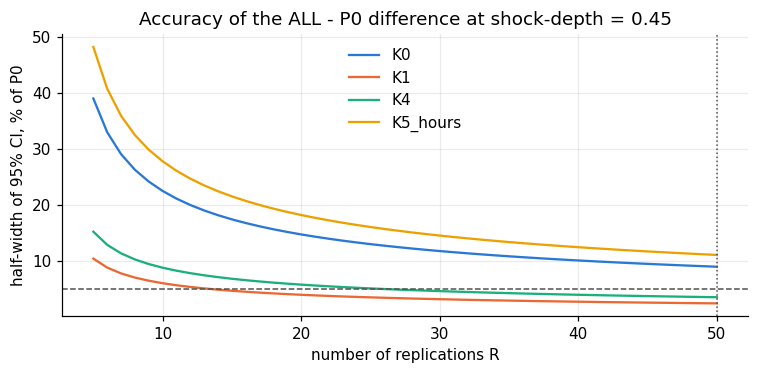

In [19]:
# Half-width of the CI of the ALL - P0 difference in % of the P0 mean as a function of R (using pilot variance)
Rs = np.arange(5, 51)
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, k in enumerate(["K0", "K1", "K4", "K5_hours"]):
    sd = (wide[(k, "ALL")] - wide[(k, "P0")]).std()
    m0 = wide[(k, "P0")].mean()
    if m0 > 0:
        ax.plot(Rs, 100 * stats.t.ppf(1 - ALPHA / 2, Rs - 1) * sd / np.sqrt(Rs) / m0, color=C[i], label=k)
ax.axhline(100 * DELTA, color="#52514e", lw=1, ls="--"); ax.axvline(R_SCREEN, color="#52514e", lw=1, ls=":")
ax.set_xlabel("number of replications R"); ax.set_ylabel("half-width of 95% CI, % of P0")
ax.set_title("Accuracy of the ALL - P0 difference at shock-depth = 0.45"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 5. Choosing

What we are choosing between: a full factorial design or a half-replicate design. In a full factorial design, all combinations of factors are tested, while in a half-replicate design, only half of the combinations are tested. The choice is made based on the number of factors and the budget for the screening stage. The rule of thumb is that **if the full factorial design fits within the budget, it is preferred because it allows for the estimation of higher-order interactions**. 

In [20]:
import itertools
SCREEN_BUDGET_H = 4.0   # how many hours we can afford for the screening stage

# We are generating a full factorial design for 5 factors,
# each with 2 levels (-1 and 1).

# contains all possible combinations of these levels.
full = np.array(list(itertools.product([-1, 1], repeat=5)))

# create a half-fractional factorial design
# by selecting only those combinations where
# the last factor (E) is equal to the product of the first four factors (A, B, C, D).
half = full[full[:, 4] == full[:, 0] * full[:, 1]
            * full[:, 2] * full[:, 3]]   # E = ABCD
# X contains the main effects and pairwise interactions for the half-fractional factorial design.
X = np.column_stack([half] + [half[:, i] * half[:, j]
                    for i, j in itertools.combinations(range(5), 2)])

# check that the design matrix X is orthogonal,
# meaning that the main effects and pairwise interactions are not confounded.
check("2^(5-1): main effects and pairwise interactions are not confounded",
      # orthogonality check: X'X = nI
      np.allclose(X.T @ X, len(half) * np.eye(X.shape[1])))  

nS = len(SHOCK_LEVELS)

plan = pd.DataFrame([
    # stages reflect the experimental design
    #  number of shock levels and replications.
    {"stage": "1. screening, full 2^5", "runs": 32 * nS * R_SCREEN},
    {"stage": "1. screening, 2^(5-1) V", "runs": 16 * nS * R_SCREEN},
    {"stage": "2. levels: 4 families x 60 LHS x 10 seeds", "runs": 4 * 60 * nS * 10},
    {"stage": "3. robustness: 9 strategies x 100 LHS x 3 seeds",
        "runs": 9 * 100 * nS * 3},
    {"stage": "5. validation: 9 strategies x 30 new seeds", "runs": 9 * nS * 30},
])
plan["hours"] = (plan["runs"] / RUNS_PER_HOUR).round(1)
SCREENING_DESIGN = "full" if plan.loc[0,
                                      "hours"] <= SCREEN_BUDGET_H else "half_resV"
print(f"Throughput: {RUNS_PER_HOUR:.0f} runs/h on {N_WORKERS} processes")
print("Screening decision:", "full factorial 2^5" if SCREENING_DESIGN ==
      "full" else "half-replicate 2^(5-1), resolution V")
plan

PASS 2^(5-1): main effects and pairwise interactions are not confounded
Throughput: 164 runs/h on 1 processes
Screening decision: half-replicate 2^(5-1), resolution V


,stage,runs,hours
0,"1. screening, full 2^5",4800,29.2
1,"1. screening, 2^(5-1) V",2400,14.6
2,2. levels: 4 families x 60 LHS x 10 seeds,7200,43.8
3,3. robustness: 9 strategies x 100 LHS x 3 seeds,8100,49.3
4,5. validation: 9 strategies x 30 new seeds,810,4.9


## 6. Basic P0 - normalization point

All measures are turned off, nominal uncertainty, three levels of shock, the first `R_SCREEN` seeds of the screening pool. These same runs are the angle of the factorial plan of stage 1, no need to recalculate them (the `run_id` match).

Normally, the KPIs are normalized to the baseline P0 (no measures, nominal uncertainty, three levels of shock). The normalization is done by dividing the KPIs by the mean of the baseline P0 for the same shock depth and the same point of uncertainty at stage 3. The normalized KPIs are then used to compare the effects of different measures and uncertainty levels.

In [21]:
scr_seeds = SEEDS["screening"][:R_SCREEN]
base_jobs = [job(s, "P0", shock=sh, stage="screening") for sh in SHOCK_LEVELS for s in scr_seeds]
br.run_jobs(base_jobs, CFG, OUT_DIR / "baseline_P0.csv", n_workers=N_WORKERS, link=link, log_every=60)
BASE = br.read_results(OUT_DIR / "baseline_P0.csv")

def ci(x):
    x = np.asarray(x, float)
    h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return pd.Series({"mean": x.mean(), "ci95": h, "min": x.min(), "max": x.max()})

cols = ["K0", "K1", "K4", "K5_hours", "K0@90", "price", "dry_share"]
BASE_SUMMARY = BASE.groupby("shock")[cols].apply(lambda g: g.apply(ci)).unstack().round(2)
BASE_SUMMARY.to_csv(OUT_DIR / "baseline_P0_summary.csv", encoding="utf-8-sig")
print("Market capacity loss:", BASE.groupby("shock")["capacity_loss"].first().round(3).to_dict())
BASE_SUMMARY

22:22:12 already done: 150, remaining: 0


Market capacity loss: {0.2: 0.074, 0.45: 0.167, 0.7: 0.259}


K0                                        K1                                            K4                                      K5_hours  \
            mean     ci95       min        max        mean      ci95        min         max         mean       ci95         min          max      mean   
shock                                                                                                                                                    
0.20      686.29   251.66      0.00    3928.60   371655.56   9374.01  303946.48   441999.21   2318516.89   76914.02  1784146.02   2990317.71  13987.16   
0.45    33613.51  2916.66  13485.95   58458.04   792371.35  13524.57  663881.71   886718.65   6614657.13  161035.87  5193800.55   7945306.80  14082.65   
0.70   110973.46  5632.81  64641.18  175950.39  1178458.98  20257.06  986716.36  1312207.69  12741524.65  388843.34  9503878.78  15595098.52  38300.27   

                                         K0@90                               price                   dry_share                    
           ci95       min        max      mean     ci95       min        max  mean  ci95   min   max      mean  ci95   min   max  
shock                                                                                                                             
0.20     530.03  11223.66   18010.34    452.55   174.80      0.00    2873.90  1.43  0.04  1.20  1.83      0.22  0.04  0.08  0.85  
0.45     893.70  10293.14   24064.51  22942.76  1682.79  11385.33   39296.13  2.31  0.18  1.47  3.76      0.68  0.09  0.22  1.00  
0.70   10910.06  13388.78  214178.02  80678.14  3648.11  54030.24  114926.97  3.45  0.25  2.05  5.00      0.76  0.06  0.38  1.00

## 7. Preparation summary

Everything needed for the next stages and the Experimental design section of the report: versions, model hash, constants, seed, horizon, R, processes, decision on the plan, results of checks. The next stages read `prep_summary.json` and check that the model hash has not changed.


In [22]:
import importlib.metadata as im
def _pkg_version(name):
    try:
        return im.version(name)
    except im.PackageNotFoundError:
        return "unknown"

PREP = {
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "netlogo_version": NETLOGO_VERSION, "model_file": MODEL_PATH.name, "model_sha256": MODEL_SHA256,
    "python": sys.version.split()[0], "pynetlogo": _pkg_version("pynetlogo"),
    "horizon": HORIZON, "checkpoints": CHECKPOINTS, "shock_levels": SHOCK_LEVELS, "shock_mid": SHOCK_MID,
    "lever_on": LEVER_ON, "lever_ranges": LEVER_RANGES, "unc_ranges": UNC_RANGES, "c3_range": C3_RANGE,
    "interface_defaults": INTERFACE_DEFAULTS, "nominal_uncertain": NOMINAL_UNC, "constants": CONSTANTS,
    "master_seed": MASTER_SEED, "r_screen": R_SCREEN, "delta": DELTA,
    "n_workers": N_WORKERS, "runs_per_hour": RUNS_PER_HOUR, "screening_design": SCREENING_DESIGN,
    "checks": CHECKS,
}
def _json_default(obj):
    # NetLogo/JVM strings are not recognized as Python strings by json.dumps.
    if type(obj).__name__ == "String" or type(obj).__module__.startswith("java."):
        return str(obj)

    if isinstance(obj, np.generic):
        return obj.item()

    return float(obj)


def _json_default(obj):
    if isinstance(obj, (str, int, float, bool)) or obj is None:
        return obj

    type_name = f"{type(obj).__module__}.{type(obj).__name__}"

    # JPype/NetLogo Java strings
    if type(obj).__name__.lower().endswith("string") or "java.lang.String" in type_name:
        return str(obj)

    if isinstance(obj, np.generic):
        return obj.item()

    # Java numeric/boolean wrappers
    try:
        if "Boolean" in type_name:
            return bool(obj)
        if any(t in type_name for t in ("Byte", "Short", "Integer", "Long")):
            return int(obj)
        if any(t in type_name for t in ("Float", "Double")):
            return float(obj)
    except (TypeError, ValueError):
        pass

    return str(obj)


(OUT_DIR / "prep_summary.json").write_text(
    json.dumps(PREP, indent=1, ensure_ascii=False, default=_json_default),
    encoding="utf-8",
)
n_fail = sum(not c["ok"] for c in CHECKS.values())
print(f"Checks: {len(CHECKS)}, not passed: {n_fail}")
print("Files:", sorted(p.name for p in OUT_DIR.iterdir()))

Checks: 13, not passed: 2
Files: ['baseline_P0.csv', 'baseline_P0_summary.csv', 'design_levels.csv', 'design_levels_points.csv', 'design_screening.csv', 'factors.csv', 'finalists.csv', 'levels.csv', 'levels_cells.csv', 'levels_scored.csv', 'levels_summary.json', 'pilot.csv', 'prep_summary.json', 'screening.csv', 'screening_cells.csv', 'screening_combos.csv', 'screening_effects.csv', 'screening_selection.csv', 'screening_summary.json', 'seeds.json', 'timing.csv']
